    # Part 1: data generator

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split


In [2]:
def generate_noisy_dataset(feature_funcs, true_func, x_range, n_samples, epsilon, seed=None):
    """Generate tabular data with columns x, f_1(x), ..., f_d(x), y.

    feature_funcs : list of functions f_i(x) (may be empty); each adds an input column
    true_func     : the true function f(x) used to generate y
    x_range       : (low, high) range to sample x uniformly from
    n_samples     : number of records
    epsilon       : noise level; noise ~ Uniform[-epsilon, epsilon]
    """
    rng = np.random.default_rng(seed)
    x = rng.uniform(x_range[0], x_range[1], size=n_samples)
    data = {"x": x}
    for i, f in enumerate(feature_funcs, start=1):
        data[f"f_{i}(x)"] = f(x)
    data["y"] = true_func(x) + rng.uniform(-epsilon, epsilon, size=n_samples)
    return pd.DataFrame(data)

Example: f_1(x)=x², f_2(x)=x³, f(x)=log(x), x-range [0, 1], 10 samples, noise level 0.1.

In [3]:
df = generate_noisy_dataset([lambda x: x**2, lambda x: x**3], np.log, (0.0, 1.0), 10, 0.1)
df

,x,f_1(x),f_2(x),y
0,0.185318,0.034343,0.006364,-1.769539
1,0.700558,0.490781,0.343820,-0.452297
2,0.076830,0.005903,0.000454,-2.481668
3,0.104450,0.010910,0.001140,-2.312110
4,0.720654,0.519342,0.374266,-0.305480
5,0.870159,0.757176,0.658864,-0.105033
6,0.342585,0.117365,0.040207,-1.043781
7,0.667132,0.445065,0.296917,-0.309458
8,0.034503,0.001190,0.000041,-3.437841
9,0.476066,0.226639,0.107895,-0.698578


Split into 80% training and 20% testing, with a fixed random state so the partitioning is the same across repeated experiments.

In [4]:
X = df.drop(columns="y")
y = df["y"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)
print(len(X_train), "train /", len(X_test), "test")

8 train / 2 test


# Part 2: linear regression

In [5]:
train_df = X_train.assign(y=y_train)
test_df = X_test.assign(y=y_test)

In [6]:
def fit(train_df):
    """Return the weight vector beta = (X^T X)^-1 X^T Y for a dataset with label column 'y'."""
    X = train_df.drop(columns="y").to_numpy()
    Y = train_df["y"].to_numpy()
    X = np.column_stack([np.ones(X.shape[0]), X])  # column of 1s for the intercept
    return np.linalg.inv(X.T @ X) @ X.T @ Y


def predict(beta, test_df):
    """Return y_pred = beta . x for every record (a 'y' column, if present, is ignored)."""
    X = test_df.drop(columns="y", errors="ignore").to_numpy()
    X = np.column_stack([np.ones(X.shape[0]), X])
    return X @ beta


def evaluate_model(predictions, true_values):
    """Root mean square error."""
    diff = np.asarray(predictions) - np.asarray(true_values)
    return np.sqrt(np.sum(diff ** 2) / len(diff))

In [7]:
beta = fit(train_df)
print("weights:", beta)
print("train RMSE:", evaluate_model(predict(beta, train_df), train_df["y"]))
print("test RMSE:", evaluate_model(predict(beta, test_df), test_df["y"]))

weights: [ -3.18085546   9.73244446 -12.29199915   5.92665036]
train RMSE: 0.04752995986987769
test RMSE: 0.4094376113273403


# Part 3: regression tree


In [8]:
import matplotlib.pyplot as plt


class _Node:
    def __init__(self, value, n, feature=None, threshold=None, left=None, right=None):
        self.n = n                  # number of training records at this node
        self.value = value          # mean y of the records at this node
        self.feature = feature      # column index of the split attribute (None for a leaf)
        self.threshold = threshold  # go left if x[feature] <= threshold
        self.left = left
        self.right = right


class RegressionTree:
    def fit(self, dataset, min_records):
        """Build the tree on a dataset with label column 'y'."""
        self.columns = [c for c in dataset.columns if c != "y"]
        X = dataset[self.columns].to_numpy(dtype=float)
        Y = dataset["y"].to_numpy(dtype=float)
        self.min_records = min_records
        self._X, self._Y = X, Y  # kept for visualize()
        self.root = self._build(X, Y)
        return self

    def _build(self, X, Y):
        node = _Node(value=Y.mean(), n=len(Y))
        if len(Y) < self.min_records:
            return node
        best = self._best_split(X, Y)
        if best is None:
            return node
        _, j, t = best
        mask = X[:, j] <= t
        node.feature, node.threshold = j, t
        node.left = self._build(X[mask], Y[mask])
        node.right = self._build(X[~mask], Y[~mask])
        return node

    @staticmethod
    def _best_split(X, Y):
        """Return (score, feature, threshold) minimizing SSE(left)+SSE(right), or None."""
        n = len(Y)
        best = None
        for j in range(X.shape[1]):
            order = np.argsort(X[:, j], kind="stable")
            xs, ys = X[order, j], Y[order]
            # prefix sums give the SSE of every left/right partition in O(n)
            cs, cs2 = np.cumsum(ys), np.cumsum(ys ** 2)
            for i in range(1, n):  # left = first i records
                if xs[i - 1] == xs[i]:
                    continue  # cannot separate identical x-values
                nl, nr = i, n - i
                sl, sr = cs[i - 1], cs[-1] - cs[i - 1]
                sse_l = cs2[i - 1] - sl ** 2 / nl
                sse_r = (cs2[-1] - cs2[i - 1]) - sr ** 2 / nr
                score = sse_l + sse_r
                if best is None or score < best[0]:
                    best = (score, j, (xs[i - 1] + xs[i]) / 2)
        return best

    def _predict_one(self, x):
        node = self.root
        while node.feature is not None:
            node = node.left if x[node.feature] <= node.threshold else node.right
        return node.value

    def predict(self, X):
        """Predict for a DataFrame (a 'y' column is ignored) or a 2-D array."""
        if isinstance(X, pd.DataFrame):
            X = X[self.columns].to_numpy(dtype=float)
        X = np.asarray(X, dtype=float)
        return np.array([self._predict_one(x) for x in X])

    def _splits(self, node=None, out=None):
        """All (feature index, threshold) split points in the tree."""
        node = self.root if node is None else node
        out = [] if out is None else out
        if node.feature is not None:
            out.append((node.feature, node.threshold))
            self._splits(node.left, out)
            self._splits(node.right, out)
        return out

    def leaf_sizes(self, node=None):
        """Number of training records in each leaf."""
        node = self.root if node is None else node
        if node.feature is None:
            return [node.n]
        return self.leaf_sizes(node.left) + self.leaf_sizes(node.right)

    def n_nodes(self):
        return 2 * len(self.leaf_sizes()) - 1  # a binary tree with L leaves has 2L-1 nodes

    def visualize(self, ax=None, true_func=None, features=None):
        """x-y plot: training data, optional true function, the tree's predictions over the
        x-range, and the split points. The first column must be x.
        features: function mapping an array of x-values to a DataFrame with the tree's
        columns (needed if the tree uses more than the attribute x, e.g. x^2, x^3)."""
        x, y = self._X[:, 0], self._Y
        grid = np.linspace(x.min(), x.max(), 1000)
        G = pd.DataFrame({"x": grid}) if features is None else features(grid)[self.columns]
        own_figure = ax is None
        if own_figure:
            _, ax = plt.subplots(figsize=(7, 4))
        ax.scatter(x, y, s=6, alpha=0.4, label="training data")
        if true_func is not None:
            ax.plot(grid, true_func(grid), "k--", label="true function")
        ax.plot(grid, self.predict(G), "r", label="tree prediction")
        for k, (j, t) in enumerate(self._splits()):
            # location of the split on the x-axis (columns are monotone in x on [0, 1])
            xs = np.interp(t, G.iloc[:, j].to_numpy(), grid)
            ax.axvline(xs, color="gray", linestyle="--", linewidth=0.5, alpha=0.6,
                       label="split points" if k == 0 else None)
        ax.set_xlabel("x"); ax.set_ylabel("y")
        if own_figure:
            ax.legend(); plt.show()


train RMSE: 0.1025665246371727
test RMSE: 0.7379924377087387


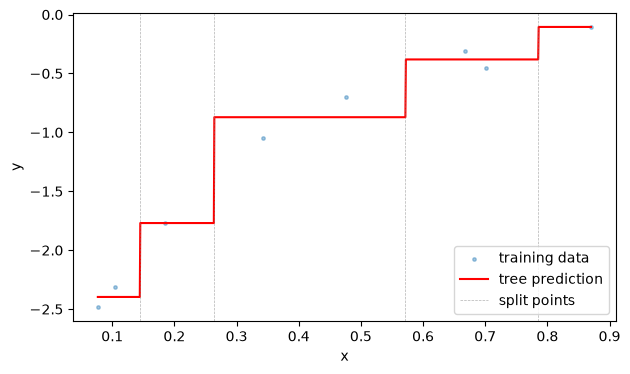

In [9]:
tree = RegressionTree().fit(train_df[["x", "y"]], min_records=3)
print("train RMSE:", evaluate_model(tree.predict(train_df[["x"]]), train_df["y"]))
print("test RMSE:", evaluate_model(tree.predict(test_df[["x"]]), test_df["y"]))
tree.visualize()

Linear: f(x) = 2x + 1, noise=0.01: weights=[1.0003 2.0001], train RMSE=0.0059, test RMSE=0.0054
Linear: f(x) = 2x + 1, noise=0.1: weights=[1.0034 2.0009], train RMSE=0.0588, test RMSE=0.0542
Cubic: f(x) = 0.5x³ - x² + x, noise=0.01: weights=[0.065  0.4533], train RMSE=0.0217, test RMSE=0.0215
Cubic: f(x) = 0.5x³ - x² + x, noise=0.1: weights=[0.068  0.4541], train RMSE=0.0623, test RMSE=0.0594


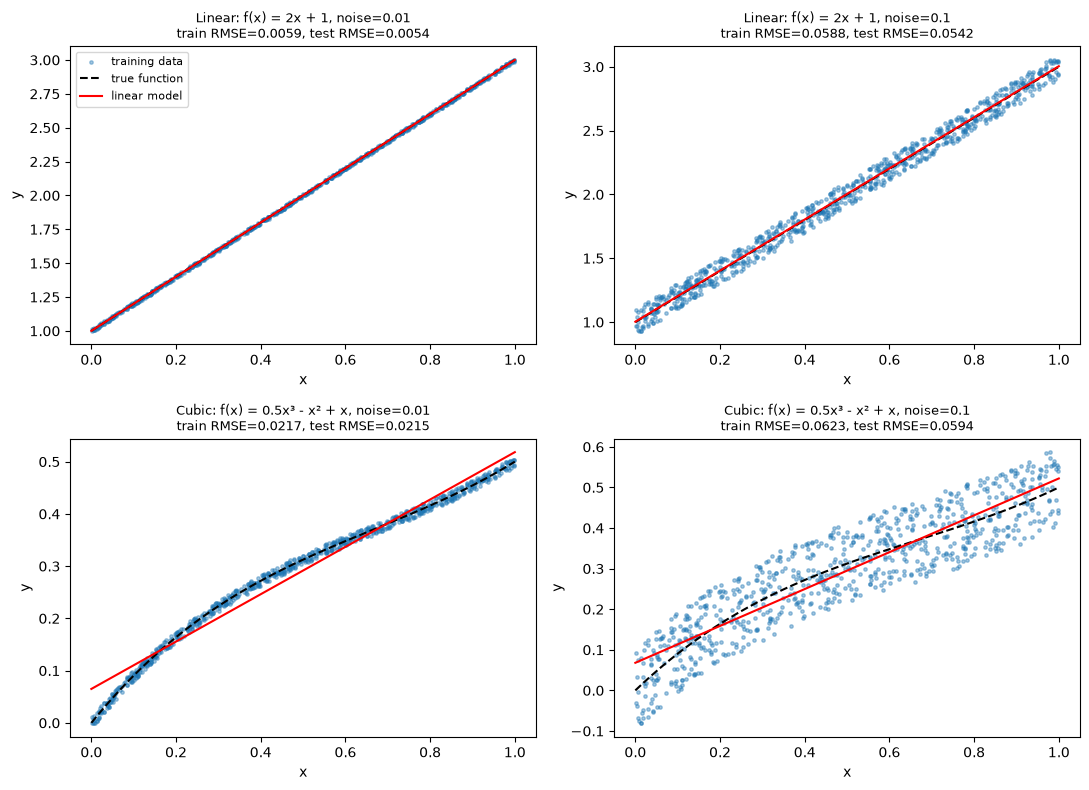

In [10]:
import matplotlib.pyplot as plt

true_functions = {
    "Linear: f(x) = 2x + 1": lambda x: 2 * x + 1,
    "Cubic: f(x) = 0.5x³ - x² + x": lambda x: 0.5 * x**3 - x**2 + x,
}
noise_levels = [0.01, 0.1]
SEED = 42  # fixed seed: same data and same train/test partitioning on every run

fig, axes = plt.subplots(len(true_functions), len(noise_levels), figsize=(11, 8))
grid = np.linspace(0, 1, 200)
for r, (fname, f) in enumerate(true_functions.items()):
    for c, eps in enumerate(noise_levels):
        data = generate_noisy_dataset([], f, (0.0, 1.0), 1000, eps, seed=SEED)
        Xtr, Xte, ytr, yte = train_test_split(data.drop(columns="y"), data["y"], test_size=0.2, random_state=SEED)
        tr, te = Xtr.assign(y=ytr), Xte.assign(y=yte)

        beta = fit(tr)
        train_rmse = evaluate_model(predict(beta, tr), tr["y"])
        test_rmse = evaluate_model(predict(beta, te), te["y"])
        print(f"{fname}, noise={eps}: weights={np.round(beta, 4)}, train RMSE={train_rmse:.4f}, test RMSE={test_rmse:.4f}")
        ax = axes[r, c]
        ax.scatter(tr["x"], tr["y"], s=6, alpha=0.4, label="training data")
        ax.plot(grid, f(grid), "k--", label="true function")
        ax.plot(grid, predict(beta, pd.DataFrame({"x": grid})), "r", label="linear model")
        ax.set_title(f"{fname}, noise={eps}" + chr(10) + f"train RMSE={train_rmse:.4f}, test RMSE={test_rmse:.4f}", fontsize=9)
        ax.set_xlabel("x"); ax.set_ylabel("y")
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

Linear: f(x) = 2x + 1, noise=0.01: weights=[ 0.9999  2.0075 -0.0219  0.0161], train RMSE=0.0059, test RMSE=0.0054
Linear: f(x) = 2x + 1, noise=0.1: weights=[ 0.999   2.0751 -0.2189  0.1613], train RMSE=0.0587, test RMSE=0.0543
Cubic: f(x) = 0.5x³ - x² + x, noise=0.01: weights=[-1.0000e-04  1.0075e+00 -1.0219e+00  5.1610e-01], train RMSE=0.0059, test RMSE=0.0054
Cubic: f(x) = 0.5x³ - x² + x, noise=0.1: weights=[-1.0000e-03  1.0751e+00 -1.2189e+00  6.6130e-01], train RMSE=0.0587, test RMSE=0.0543


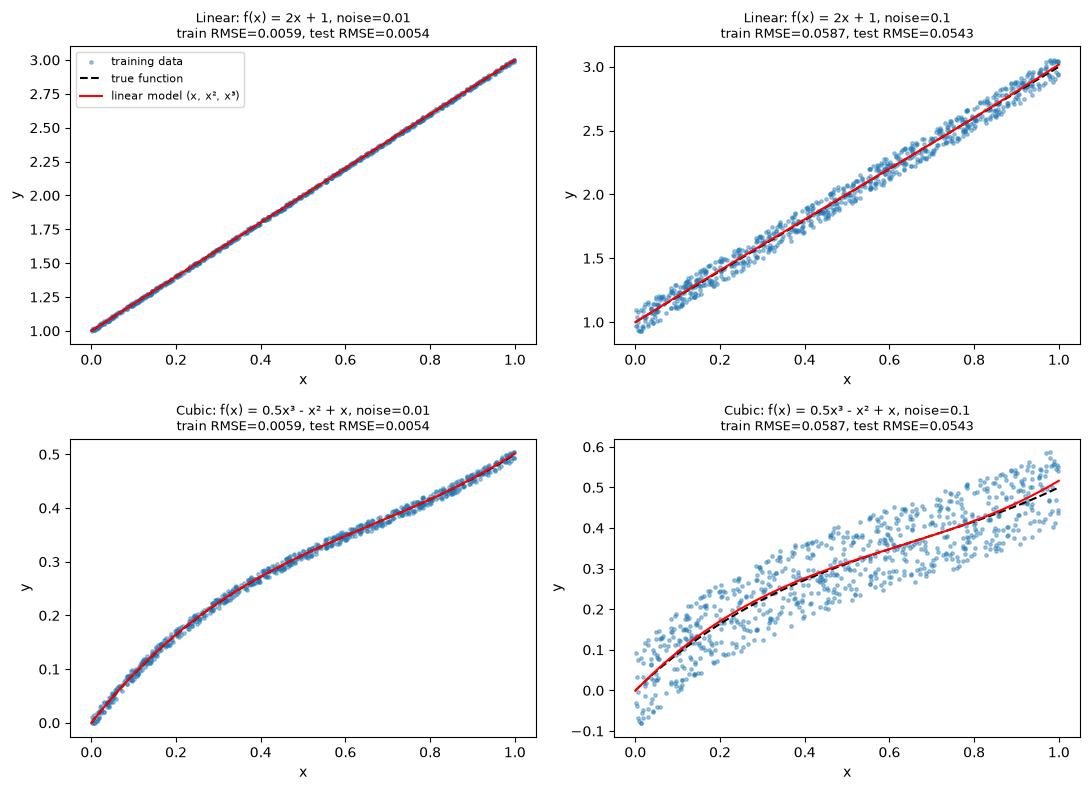

,true function,noise,test RMSE (x only),"test RMSE (x, x², x³)"
0,Linear: f(x) = 2x + 1,0.01,0.0054,0.0054
1,Linear: f(x) = 2x + 1,0.10,0.0542,0.0543
2,Cubic: f(x) = 0.5x³ - x² + x,0.01,0.0215,0.0054
3,Cubic: f(x) = 0.5x³ - x² + x,0.10,0.0594,0.0543


In [11]:
extra_funcs = [lambda x: x**2, lambda x: x**3]
comparison = []

fig, axes = plt.subplots(len(true_functions), len(noise_levels), figsize=(11, 8))
for r, (fname, f) in enumerate(true_functions.items()):
    for c, eps in enumerate(noise_levels):
        # same seed and x-range as Part 4 -> identical x, y; extras only add columns
        data = generate_noisy_dataset(extra_funcs, f, (0.0, 1.0), 1000, eps, seed=SEED)
        Xtr, Xte, ytr, yte = train_test_split(data.drop(columns="y"), data["y"], test_size=0.2, random_state=SEED)
        tr, te = Xtr.assign(y=ytr), Xte.assign(y=yte)

        beta = fit(tr)
        train_rmse = evaluate_model(predict(beta, tr), tr["y"])
        test_rmse = evaluate_model(predict(beta, te), te["y"])

        # baseline: same data using only the x column
        beta0 = fit(tr[["x", "y"]])
        base_test = evaluate_model(predict(beta0, te[["x"]]), te["y"])
        comparison.append({"true function": fname, "noise": eps,
                           "test RMSE (x only)": base_test, "test RMSE (x, x², x³)": test_rmse})
        print(f"{fname}, noise={eps}: weights={np.round(beta, 4)}, train RMSE={train_rmse:.4f}, test RMSE={test_rmse:.4f}")

        # plot the entire function beta0 + beta1*x + beta2*x^2 + beta3*x^3
        grid_df = pd.DataFrame({"x": grid, "f_1(x)": grid**2, "f_2(x)": grid**3})
        ax = axes[r, c]
        ax.scatter(tr["x"], tr["y"], s=6, alpha=0.4, label="training data")
        ax.plot(grid, f(grid), "k--", label="true function")
        ax.plot(grid, predict(beta, grid_df), "r", label="linear model (x, x², x³)")
        ax.set_title(f"{fname}, noise={eps}" + chr(10) + f"train RMSE={train_rmse:.4f}, test RMSE={test_rmse:.4f}", fontsize=9)
        ax.set_xlabel("x"); ax.set_ylabel("y")
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

pd.DataFrame(comparison).round(4)

In [12]:
x_new = 10.0
rows = []
for fname, f in true_functions.items():
    for eps in noise_levels:
        for label, funcs in [("(x, y)", []), ("(x, x², x³, y)", extra_funcs)]:
            data = generate_noisy_dataset(funcs, f, (0.0, 1.0), 1000, eps, seed=SEED)
            Xtr, _, ytr, _ = train_test_split(data.drop(columns="y"), data["y"], test_size=0.2, random_state=SEED)
            beta = fit(Xtr.assign(y=ytr))
            point = {"x": [x_new]}
            for i, g in enumerate(funcs, start=1):
                point[f"f_{i}(x)"] = g(np.array([x_new]))
            pred = predict(beta, pd.DataFrame(point))[0]
            rows.append({"true function": fname, "noise": eps, "data": label,
                         "prediction": pred, "f(10)": f(x_new), "error": pred - f(x_new)})
pd.DataFrame(rows).round(3)

,true function,noise,data,prediction,f(10),error
0,Linear: f(x) = 2x + 1,0.01,"(x, y)",21.001,21.0,0.001
1,Linear: f(x) = 2x + 1,0.01,"(x, x², x³, y)",35.018,21.0,14.018
2,Linear: f(x) = 2x + 1,0.10,"(x, y)",21.013,21.0,0.013
3,Linear: f(x) = 2x + 1,0.10,"(x, x², x³, y)",161.181,21.0,140.181
4,Cubic: f(x) = 0.5x³ - x² + x,0.01,"(x, y)",4.598,410.0,-405.402
5,Cubic: f(x) = 0.5x³ - x² + x,0.01,"(x, x², x³, y)",424.018,410.0,14.018
6,Cubic: f(x) = 0.5x³ - x² + x,0.10,"(x, y)",4.609,410.0,-405.391
7,Cubic: f(x) = 0.5x³ - x² + x,0.10,"(x, x², x³, y)",550.181,410.0,140.181


**Which case is "good"?** The prediction is good only when the model class matches the true function.

- **Linear true function:** the (x, y) model is good (error ≈ 0.001 to 0.013). The extra-column model is bad (error ≈ 14 and 140): it fits small spurious x² and x³ weights, which get multiplied by 100 and 1000 at x = 10.
- **Cubic true function:** the (x, x², x³, y) model is the only reasonable one, and it is good only at low noise (error ≈ 14 on f(10) = 410, about 3.4%). At noise 0.1 it is off by ≈ 140. The (x, y) model is off by ≈ 405 because a straight line cannot capture the curvature.

Extrapolating far outside the training range amplifies small coefficient errors, and more so for the higher-degree model. Lower noise gives a more accurate extrapolation.

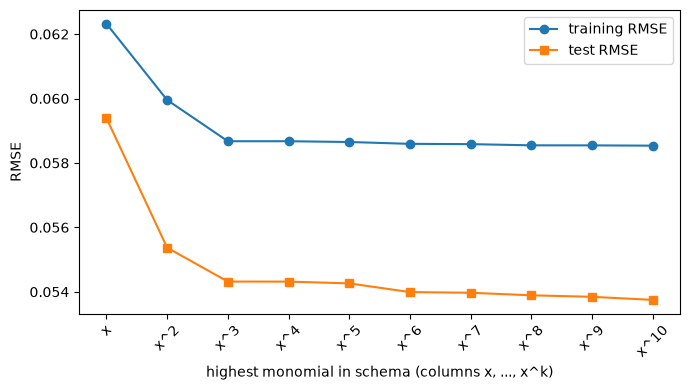

,degree,train RMSE,test RMSE
0,1,0.06232,0.05939
1,2,0.05995,0.05537
2,3,0.05867,0.05432
3,4,0.05867,0.05432
4,5,0.05865,0.05426
5,6,0.05859,0.05399
6,7,0.05858,0.05397
7,8,0.05855,0.05389
8,9,0.05855,0.05384
9,10,0.05854,0.05375


In [13]:
cubic = true_functions["Cubic: f(x) = 0.5x³ - x² + x"]
max_degree = 10
# one dataset with columns x, x^2, ..., x^10; schema k uses the first k columns
monomials = [(lambda x, p=p: x**p) for p in range(2, max_degree + 1)]
data = generate_noisy_dataset(monomials, cubic, (0.0, 1.0), 1000, 0.1, seed=SEED)
Xtr, Xte, ytr, yte = train_test_split(data.drop(columns="y"), data["y"], test_size=0.2, random_state=SEED)
tr, te = Xtr.assign(y=ytr), Xte.assign(y=yte)

degrees = list(range(1, max_degree + 1))
train_errs, test_errs = [], []
for k in degrees:
    cols = list(Xtr.columns[:k])
    beta = fit(tr[cols + ["y"]])
    train_errs.append(evaluate_model(predict(beta, tr[cols]), tr["y"]))
    test_errs.append(evaluate_model(predict(beta, te[cols]), te["y"]))

plt.figure(figsize=(7, 4))
plt.plot(degrees, train_errs, "o-", label="training RMSE")
plt.plot(degrees, test_errs, "s-", label="test RMSE")
plt.xticks(degrees, ["x"] + [f"x^{k}" for k in degrees[1:]], rotation=45)
plt.xlabel("highest monomial in schema (columns x, ..., x^k)"); plt.ylabel("RMSE")
plt.legend(); plt.tight_layout(); plt.show()
pd.DataFrame({"degree": degrees, "train RMSE": train_errs, "test RMSE": test_errs}).round(5)

**What the plot tells us:** Training error can never increase as columns are added, since each model contains the previous one. It drops from 0.062 to 0.059 at degree 3, the true degree of f, and then barely moves. Test error follows the same pattern and flattens at about the noise floor (ε/√3 ≈ 0.058), so the extra monomials past x³ add almost nothing. The two curves do not diverge here, so there is no visible overfitting. That is because 800 training points are plenty for at most 10 parameters, and the test RMSE sits slightly below the train RMSE only because of chance in which noise values landed in the 200-point test set. With a much smaller training set, the training error would keep falling while the test error would turn upward.

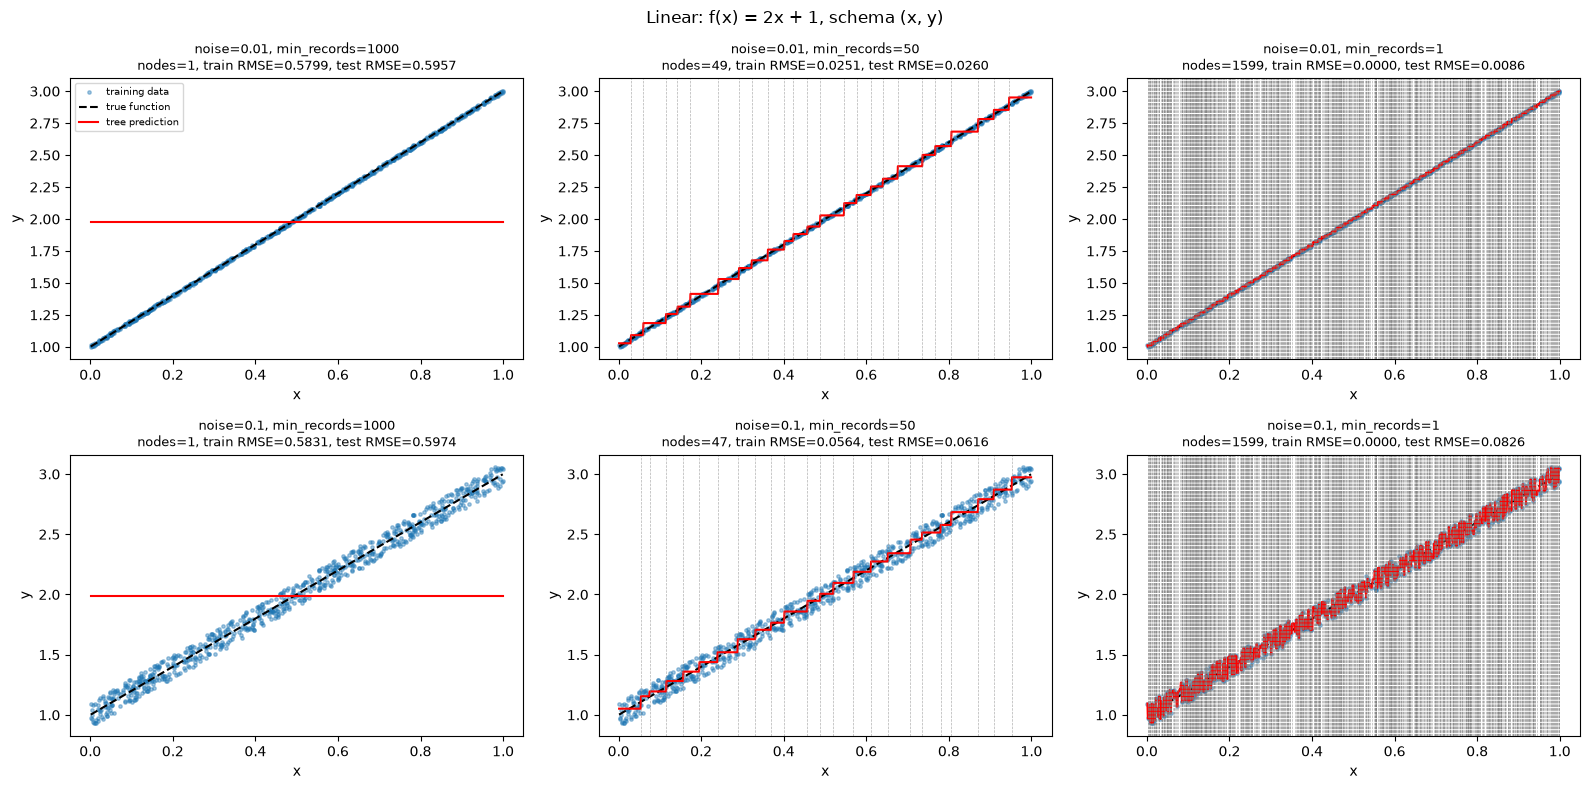

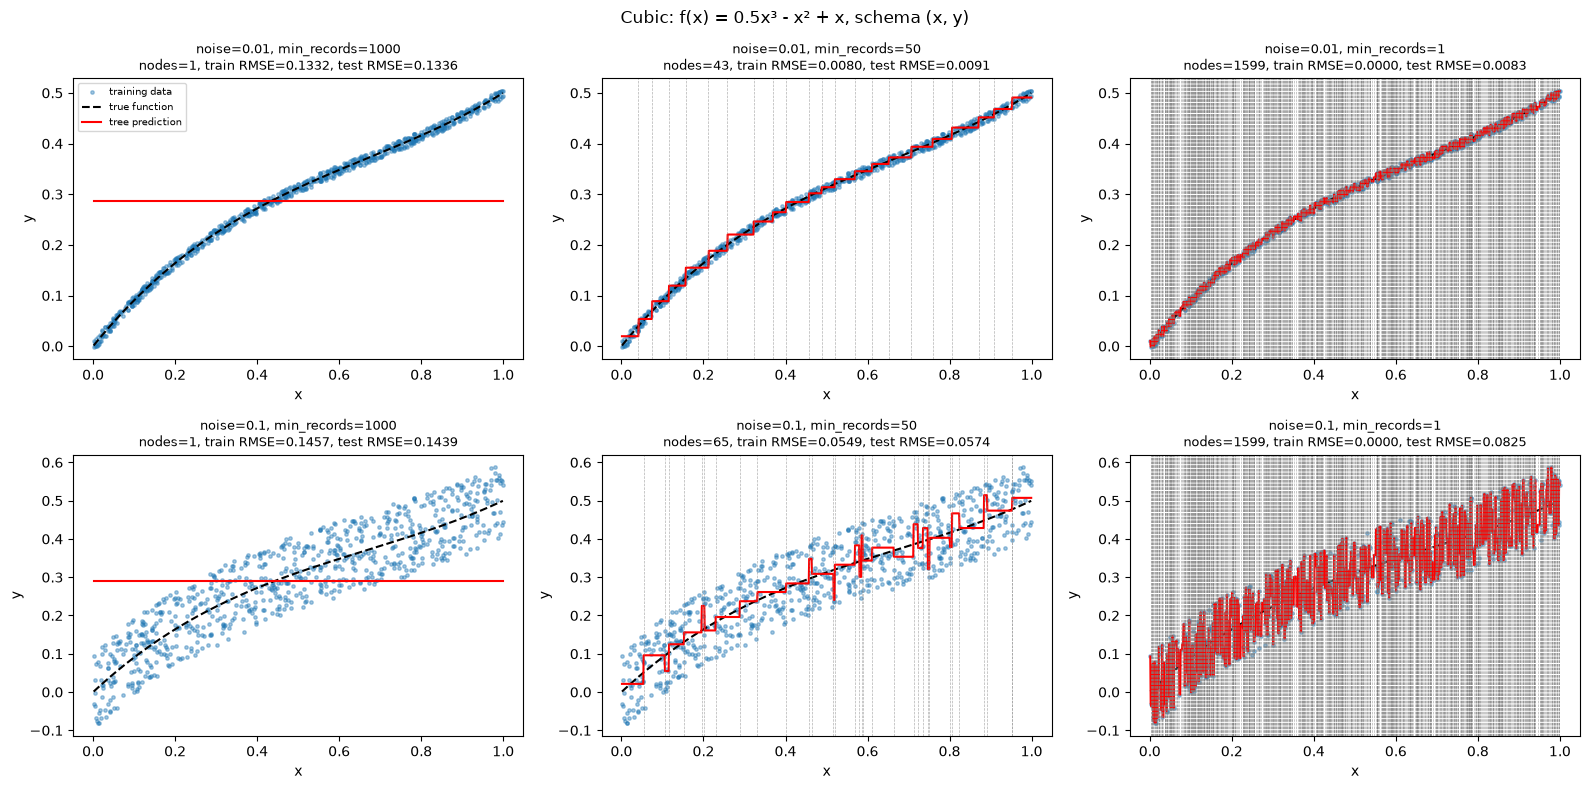

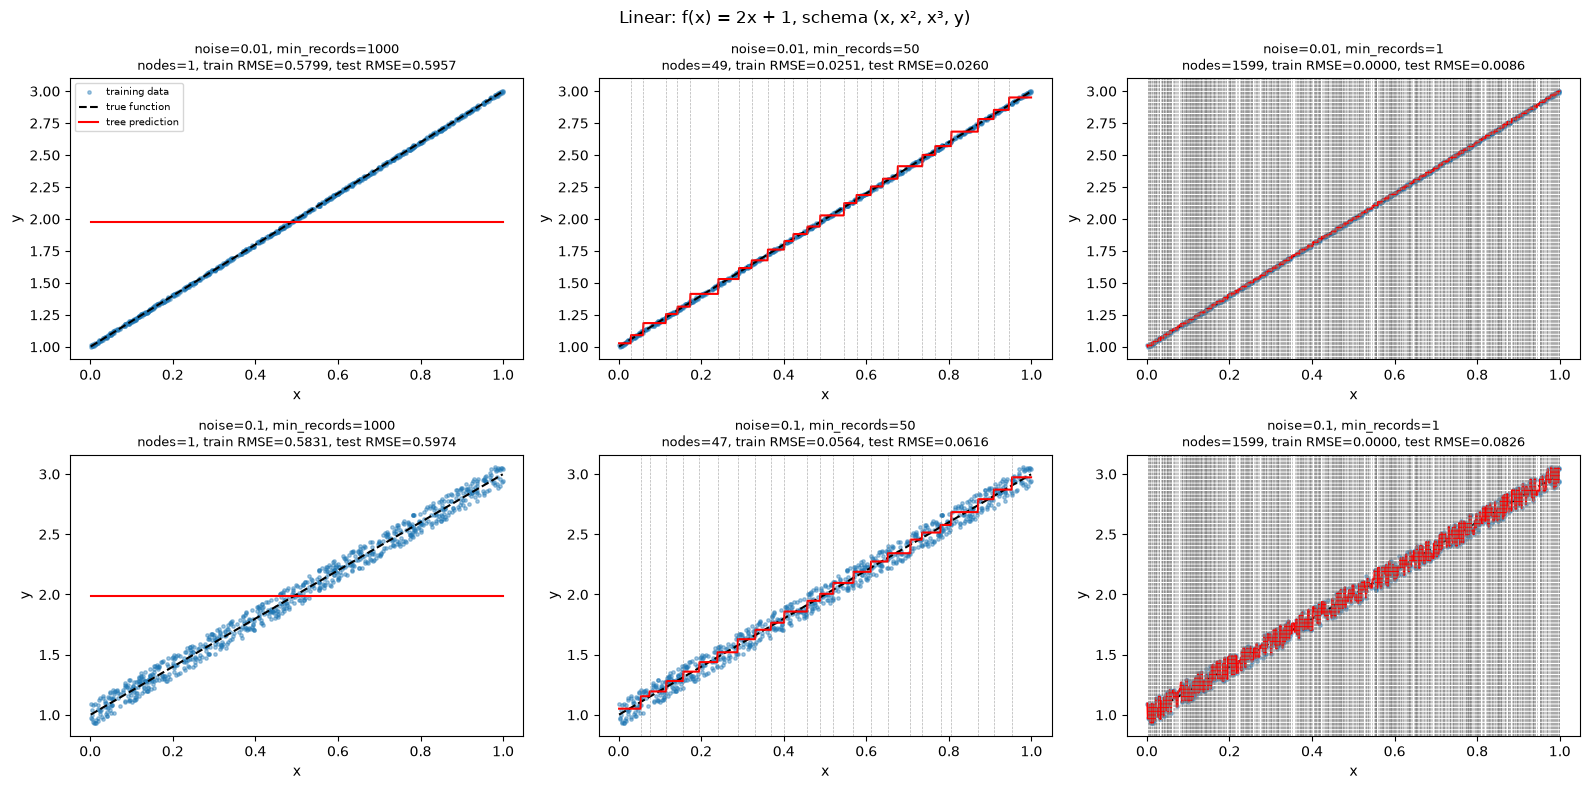

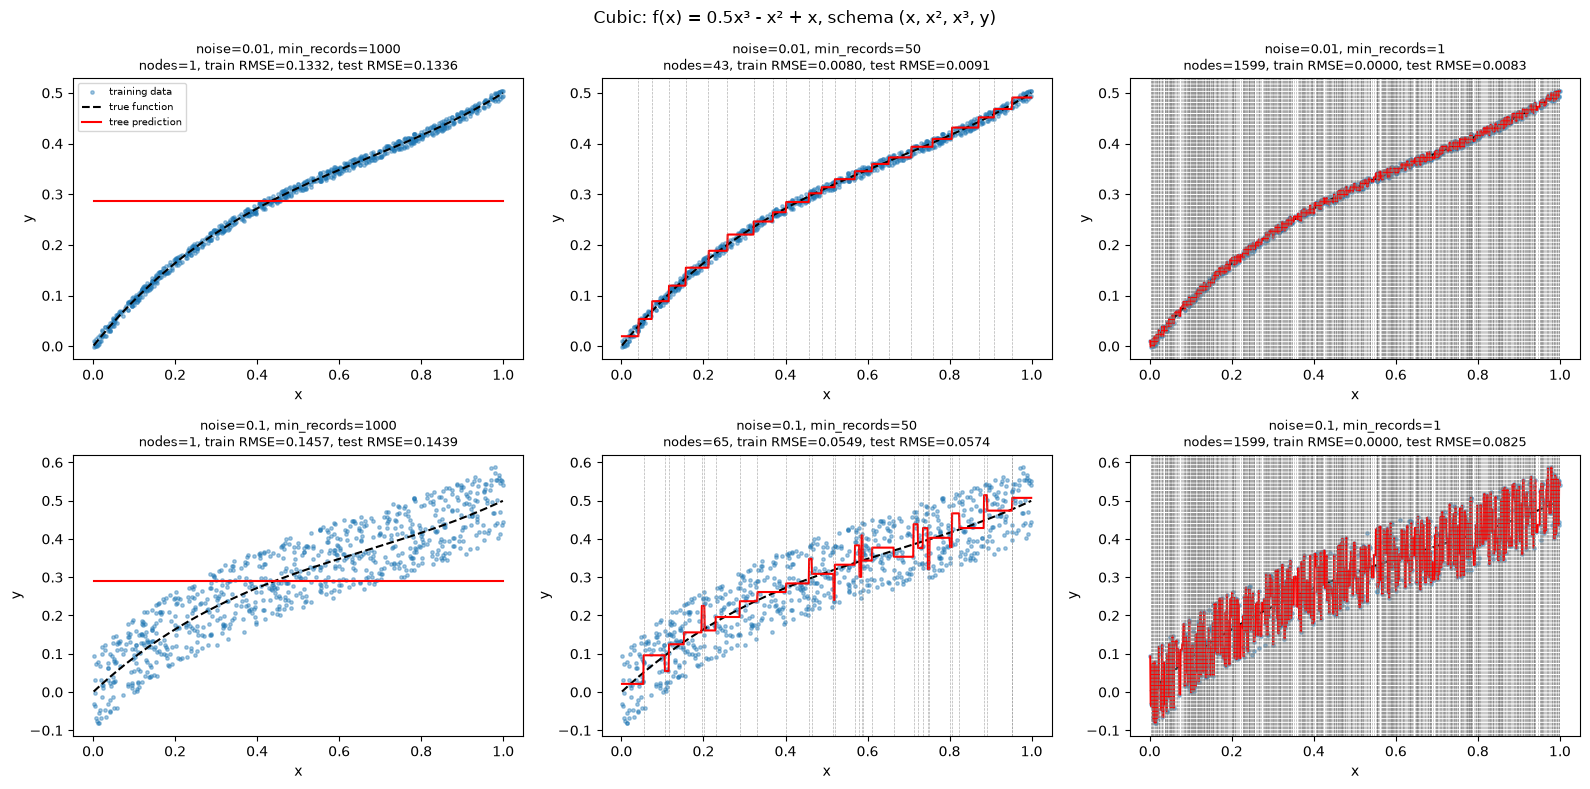

In [14]:
min_records_list = [1000, 50, 1]
make_features = lambda funcs: (lambda g: pd.DataFrame(
    {"x": g, **{f"f_{i}(x)": fn(g) for i, fn in enumerate(funcs, start=1)}}))
schemas = {"(x, y)": [], "(x, x², x³, y)": extra_funcs}

results = []
for sname, funcs in schemas.items():
    for fname, f in true_functions.items():
        fig, axes = plt.subplots(len(noise_levels), len(min_records_list), figsize=(16, 8))
        for r, eps in enumerate(noise_levels):
            data = generate_noisy_dataset(funcs, f, (0.0, 1.0), 1000, eps, seed=SEED)
            Xtr, Xte, ytr, yte = train_test_split(data.drop(columns="y"), data["y"], test_size=0.2, random_state=SEED)
            tr, te = Xtr.assign(y=ytr), Xte.assign(y=yte)
            beta = fit(tr)
            lin_train = evaluate_model(predict(beta, tr), tr["y"])
            lin_test = evaluate_model(predict(beta, te), te["y"])
            for c, m in enumerate(min_records_list):
                tree = RegressionTree().fit(tr, min_records=m)
                tree_train = evaluate_model(tree.predict(tr), tr["y"])
                tree_test = evaluate_model(tree.predict(te), te["y"])
                sizes = tree.leaf_sizes()
                results.append({"schema": sname, "true function": fname.split(":")[0], "noise": eps,
                                "min_records": m, "nodes": tree.n_nodes(), "leaves": len(sizes),
                                "leaf size min/median/max": f"{min(sizes)}/{int(np.median(sizes))}/{max(sizes)}",
                                "tree train": tree_train, "tree test": tree_test,
                                "linear train": lin_train, "linear test": lin_test})
                ax = axes[r, c]
                tree.visualize(ax=ax, true_func=f, features=make_features(funcs))
                ax.set_title(f"noise={eps}, min_records={m}" + chr(10) +
                             f"nodes={tree.n_nodes()}, train RMSE={tree_train:.4f}, test RMSE={tree_test:.4f}", fontsize=9)
        axes[0, 0].legend(fontsize=7)
        fig.suptitle(f"{fname}, schema {sname}")
        plt.tight_layout(); plt.show()

## Comparison of tree and linear model RMSE

In [15]:
results_df = pd.DataFrame(results)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 20)
results_df.round(4)

,schema,true function,noise,min_records,nodes,leaves,leaf size min/median/max,tree train,tree test,linear train,linear test
0,"(x, y)",Linear,0.01,1000,1,1,800/800/800,0.5799,0.5957,0.0059,0.0054
1,"(x, y)",Linear,0.01,50,49,25,19/30/49,0.0251,0.0260,0.0059,0.0054
2,"(x, y)",Linear,0.01,1,1599,800,1/1/1,0.0000,0.0086,0.0059,0.0054
3,"(x, y)",Linear,0.10,1000,1,1,800/800/800,0.5831,0.5974,0.0588,0.0542
4,"(x, y)",Linear,0.10,50,47,24,13/33/49,0.0564,0.0616,0.0588,0.0542
5,"(x, y)",Linear,0.10,1,1599,800,1/1/1,0.0000,0.0826,0.0588,0.0542
6,"(x, y)",Cubic,0.01,1000,1,1,800/800/800,0.1332,0.1336,0.0217,0.0215
7,"(x, y)",Cubic,0.01,50,43,22,26/34/49,0.0080,0.0091,0.0217,0.0215
8,"(x, y)",Cubic,0.01,1,1599,800,1/1/1,0.0000,0.0083,0.0217,0.0215
9,"(x, y)",Cubic,0.10,1000,1,1,800/800/800,0.1457,0.1439,0.0623,0.0594


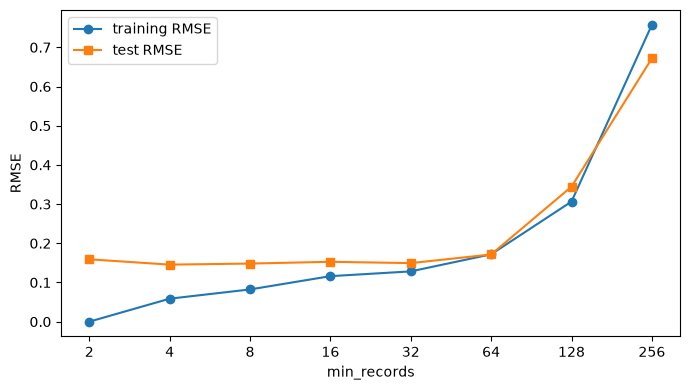

,min_records,nodes,train RMSE,test RMSE
0,2,319,0.0000,0.1591
1,4,149,0.0586,0.1455
2,8,75,0.0822,0.1482
3,16,35,0.1161,0.1528
4,32,23,0.1283,0.1494
5,64,11,0.1718,0.1714
6,128,3,0.3064,0.3445
7,256,1,0.7574,0.6717


In [16]:
sin_func = lambda x: np.sin(2 * np.pi * x)
sdata = generate_noisy_dataset([], sin_func, (0.0, 1.0), 200, 0.2, seed=SEED)
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(sdata.drop(columns="y"), sdata["y"], test_size=0.2, random_state=SEED)
s_tr, s_te = Xs_tr.assign(y=ys_tr), Xs_te.assign(y=ys_te)

mr_list = [2, 4, 8, 16, 32, 64, 128, 256]
s_train, s_test, s_nodes = [], [], []
for m in mr_list:
    t = RegressionTree().fit(s_tr, min_records=m)
    s_train.append(evaluate_model(t.predict(s_tr), s_tr["y"]))
    s_test.append(evaluate_model(t.predict(s_te), s_te["y"]))
    s_nodes.append(t.n_nodes())

plt.figure(figsize=(7, 4))
plt.plot(mr_list, s_train, "o-", label="training RMSE")
plt.plot(mr_list, s_test, "s-", label="test RMSE")
plt.xscale("log", base=2); plt.xticks(mr_list, mr_list)
plt.xlabel("min_records"); plt.ylabel("RMSE"); plt.legend(); plt.tight_layout(); plt.show()
pd.DataFrame({"min_records": mr_list, "nodes": s_nodes, "train RMSE": s_train, "test RMSE": s_test}).round(4)